# Beyond Benefits: Is Workplace Mental Health Support Really Reaching Employees?

## Goal
Investigate the relation between the mental health benefits, knowledge about the available resources and the workers trust to talk about mental health at work.

## Main question

Are tech organisations doing enough to turn mental health support into a meaningful employee experience?

## Why it matters?
As seekers of the best working conditions possible and aspiring to begin a tech career, these findings may help understand what meaningful workplace support involves.


## Research Questions
******(Remark: we have to decide which questions to keep as not all of them can be answered by our data)

1. Does having mental health benefits means to know the available resources?
2. Does the employer offer resources to learn about mental health and how to seek help?
3. Have employees discussed their mental heslth with colleagues?
4. Being afraid of negative consequences is related with reducing or avoiding to seeking for treatment? / How does being afraid of negative consequences relate to a reduction or avoidance of seeking treatment?
5. What mental health topics are most publicly communicated by tech companies?
6. How do organisations communicate the different dimensions of support?
7. Do organisations communicate about the same issues that employees identify as important or challenging?
8. Does reporting the availability of mental health benefits also correspond to reporting the availability of educational and informational resources?
9. How do companies approach mental health?

## Hypothesis
1. Employees who report that their employer provides mental health benefits are more likely to know about available workplace mental health resources.
2. A significant proportion of employees do not know whether their employer provides mental health benefits.
3. Employees who discuss mental health with colleagues are more likely to discuss it with their employer.
4. The themes emphasised in companies' public mental health communications may differ from the concerns reported by employees.
5. Organisations highlight the availability of mental health resources more often than they communicate how employees can access them.

## Sources
- OSMI Mental Health in Tech Survey
- Official pages from tech companies

## Methodology 
Exploratory and descriptive analysis with Python, supplemented by web scraping.

## Integration plan and limitations:
Our data is investigating relations between variables, not causality, as the dataset focus on employee perceptions and self reported experiences. 
The web scraping is focused on themes related with the variables on the dataset. The companies webpages describe public organisational communication, not necessarily the internal policies employees receive.

- Organisational support
1. Healthcare and financial support
   - Dataset: benefits, medical_coverage
   - What organisations communicate about insurance, treatment coverage and access to professional care
2. Education and information
   - Dataset: workplace_resources
   - What organisations communicate about awareness, mental health education and where employees can seek help
3. Workplace dialogue
   - Dataset:mh_employer_discussion, mh_coworker_discussion
   - What organisations communicate about conversations with managers, colleagues and workplace culture


In [2]:
# Action: import libraries
import pandas as pd # loading, cleaning and analysing the data
import numpy as np # numerical operations, if required
import requests # communicate with websites and web APIs using HTTP requests
import re # regular expressions for searching, matching and modifying text patterns
import time # functions for working with time, delays and timestamps

from bs4 import BeautifulSoup # parse and extract information from HTML or XML pages
from collections import Counter # counts how often items appear in an iterable

import matplotlib.pyplot as plt # creates graphs
import seaborn as sns # creates graphs

# visual configuration settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Libraries successfully imported")

Libraries successfully imported


In [9]:
# Loading the dataset and inspecting
df = pd.read_csv("/Users/sandragoncalves/Downloads/Survey dataset on mental health in tech professionals from Open Sourcing Mental Health (OSMI) surveys (2017-2021)/data.csv")

print("Dataset dimensions", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
df.info()

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False))

Dataset dimensions (1242, 11)

Columns:
['tech_company', 'benefits', 'workplace_resources', 'mh_employer_discussion', 'mh_coworker_discussion', 'medical_coverage', 'mental_health', 'mh_share', 'age', 'gender', 'country']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 1242 entries, 0 to 1241
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   tech_company            1242 non-null   str    
 1   benefits                1242 non-null   str    
 2   workplace_resources     1242 non-null   str    
 3   mh_employer_discussion  1242 non-null   str    
 4   mh_coworker_discussion  1242 non-null   str    
 5   medical_coverage        1242 non-null   str    
 6   mental_health           1242 non-null   str    
 7   mh_share                1242 non-null   int64  
 8   age                     1242 non-null   float64
 9   gender                  1242 non-null   str    
 10  country                 1242 

tech_company              0
benefits                  0
workplace_resources       0
mh_employer_discussion    0
mh_coworker_discussion    0
medical_coverage          0
mental_health             0
mh_share                  0
age                       0
gender                    0
country                   0
dtype: int64

In [60]:
df.head()

,tech_company,benefits,workplace_resources,mh_employer_discussion,mh_coworker_discussion,medical_coverage,mental_health,mh_share,age,gender,country
0,Yes,No,I don't know,No,Yes,Yes,Possibly,5,27.0,Female,United Kingdom
1,Yes,Yes,No,No,Yes,Yes,Possibly,4,31.0,Male,United Kingdom
2,Yes,I don't know,No,Yes,Yes,No,Yes,5,36.0,Male,United States of America
3,Yes,Yes,I don't know,Yes,Yes,Yes,Yes,10,22.0,Male,United States of America
4,Yes,Yes,No,No,Yes,Yes,Yes,8,36.0,Female,United States of America


## Variables (original questions retrieved from the original survey)
Understanding what each column means

| Variable | Original Question | What it measures |
|---|---|---|
| benefits | Does your employer provide mental health benefits as part of healthcare coverage? | Perceived availability of benefits |
| workplace_resources | Does your employer offer resources to learn more about mental health disorders and options for seeking help? | Perceived availability of educational and informational resources|
| mh_employer_discussion | Have you ever discussed your mental health with your employer? | Previous disclosure/discussion |
| mh_coworker_discussion | Have you ever discussed your mental health with coworkers? | Previous disclosure/discussion with colleagues |
| medical_coverage | Do you have medical coverage that includes treatment of mental health disorders? | Personal access to medical coverage | 
| mental_health | Do you currently have a mental health disorder? | Self-reported current mental health status
| mh_share | How willing would you be to share with friends and family that you have a mental illness? | Willingness to disclose to personal contacts | 

In [38]:
# Statistical Summary of the Dataset in order to understand the distributions better

print("Numerical variables:")
display(df.describe())

Numerical variables:


,mh_share,age
count,1242.000000,1242.000000
mean,6.572464,35.030598
std,2.701952,8.186624
min,0.000000,19.000000
25%,5.000000,29.000000
50%,7.000000,34.000000
75%,9.000000,40.000000
max,10.000000,66.000000


In [41]:
print("Categorical variables:")
display(df.describe(include=["str"]))

Categorical variables:


,tech_company,benefits,workplace_resources,mh_employer_discussion,mh_coworker_discussion,medical_coverage,mental_health,gender,country
count,1242,1242,1242,1242,1242,1242,1242,1242,1242
unique,2,3,3,2,2,2,4,3,30
top,Yes,Yes,No,No,No,Yes,Yes,Male,United States of America
freq,899,781,465,832,679,1147,553,813,947


In [26]:
selected_columns = ["tech_company", "benefits", "workplace_resources", "mh_employer_discussion", "medical_coverage", "mental_health"]

analysis_df = df[selected_columns].copy()

analysis_df

,tech_company,benefits,workplace_resources,mh_employer_discussion,mental_health
0,Yes,No,I don't know,No,Possibly
1,Yes,Yes,No,No,Possibly
2,Yes,I don't know,No,Yes,Yes
3,Yes,Yes,I don't know,Yes,Yes
4,Yes,Yes,No,No,Yes
...,...,...,...,...,...
1237,No,I don't know,No,No,Yes
1238,No,Yes,Yes,No,Yes
1239,No,Yes,Yes,Yes,Yes
1240,Yes,Yes,Yes,No,No


In [68]:
# Focusing the analysis in workers of tech companies, not just tech workers
analysis_df = analysis_df[
    analysis_df["tech_company"] == "Yes"
].copy()
analysis_df.shape

(899, 5)

In [93]:
# Creating a frequency table
pd.crosstab(
    analysis_df["benefits"],
    analysis_df["workplace_resources"],
    margins=True
)

workplace_resources,I don't know,No,Yes,All
benefits,,,,
I don't know,99,108,22,229
No,17,84,8,109
Yes,139,164,258,561
All,255,356,288,899


In [94]:
# Lets calculate row percentages
pd.crosstab(
    analysis_df["benefits"],
    analysis_df["workplace_resources"],
    normalize="index"
) * 100

workplace_resources,I don't know,No,Yes
benefits,,,
I don't know,43.231441,47.161572,9.606987
No,15.596330,77.064220,7.339450
Yes,24.777184,29.233512,45.989305


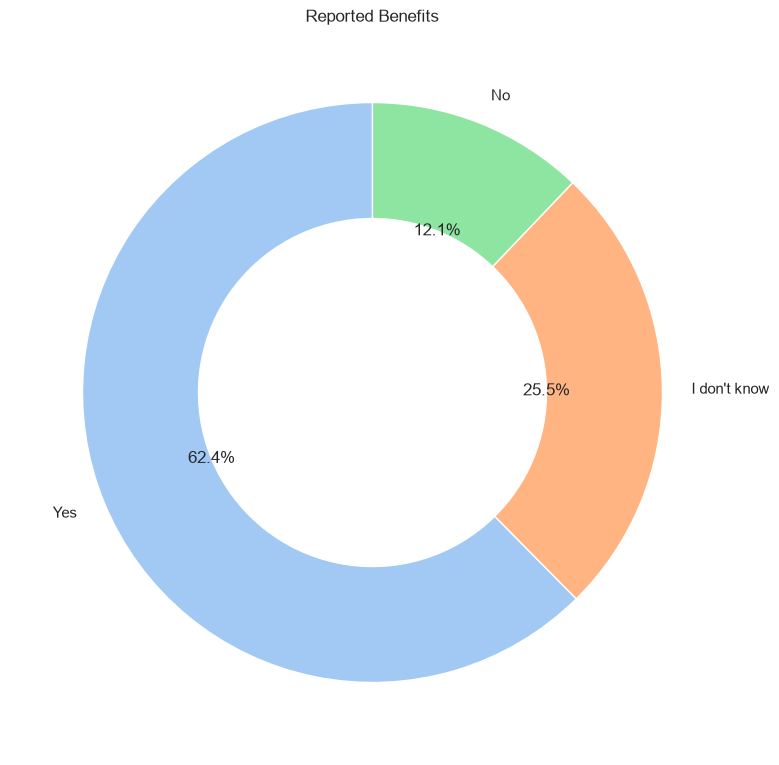

In [69]:
# Benefits pie chart
import matplotlib.pyplot as plt

benefit_counts = analysis_df["benefits"].value_counts(dropna=True)

plt.figure(figsize=(8, 8))
plt.pie(
    benefit_counts,
    labels=benefit_counts.index,
    colors=colors,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4} # I personally prefer the donut chart
)

plt.title("Reported Benefits")
plt.tight_layout()
plt.show()

In [70]:
# Analyse H1: Benefits and educational resources - counting combinations of categories
h1_table = pd.crosstab(analysis_df["benefits"],
    analysis_df["workplace_resources"],
    normalize="index"
                      ) * 100
print(h1_table)

workplace_resources  I don't know         No        Yes
benefits                                               
I don't know            43.231441  47.161572   9.606987
No                      15.596330  77.064220   7.339450
Yes                     24.777184  29.233512  45.989305


In [71]:
# Setting the graph's colours
colors = sns.color_palette("pastel")[0:5]

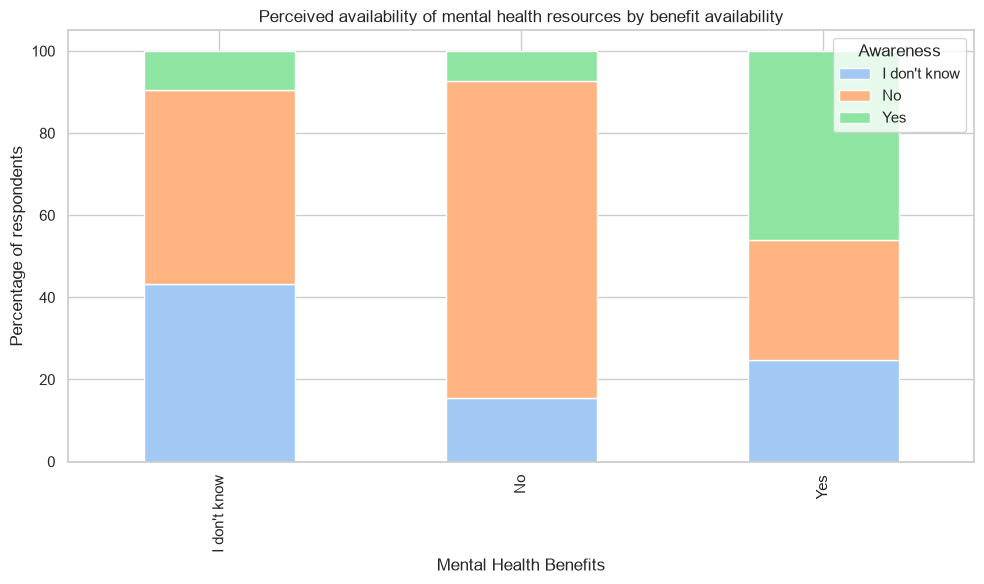

In [96]:
# Visualization of results - percentage of employees who know what support is available, grouped by benefit availability
h1_table.plot(kind="bar", color=colors, stacked=True, figsize=(10, 6))

plt.title("Perceived availability of mental health resources by benefit availability")
plt.xlabel("Mental Health Benefits")
plt.ylabel("Percentage of respondents")
plt.legend(title="Awareness")
plt.tight_layout()
plt.show()

In [73]:
# Benefits vs Mental Health
benefits_mh_table = pd.crosstab(
    analysis_df["benefits"], 
    analysis_df["mental_health"],
    normalize="index"
) * 100
display(benefits_mh_table)

mental_health,Don't Know,No,Possibly,Yes
benefits,,,,
I don't know,13.100437,35.371179,25.764192,25.764192
No,7.339450,27.522936,22.935780,42.201835
Yes,4.991087,26.381462,17.468806,51.158645


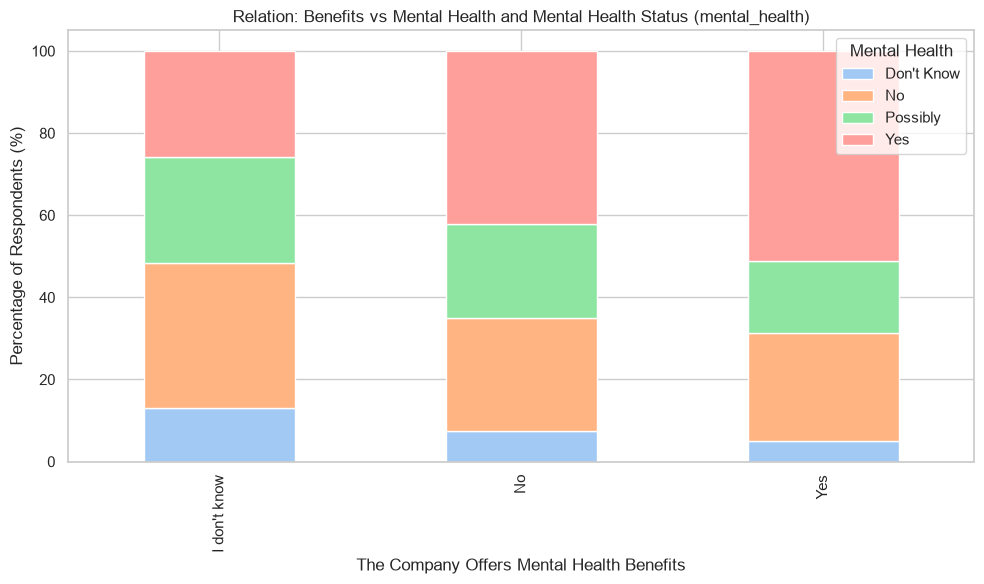

In [74]:
benefits_mh_table.plot(kind="bar", color=colors, stacked=True, figsize=(10, 6))
plt.title("Relation: Benefits vs Mental Health and Mental Health Status (mental_health)")
plt.xlabel("The Company Offers Mental Health Benefits")
plt.ylabel("Percentage of Respondents (%)")
plt.legend(title="Mental Health")
plt.tight_layout()
plt.show()

In [75]:
# Analysis: Workplace resources awareness vs mental health - 
# lets check if the employees that are aware of the available resources in the company ("workplace_resources") are more likely to state they have a mental health situaation ("mental_health")
resources_mh_table = pd.crosstab(
    analysis_df["workplace_resources"],
    analysis_df["mental_health"],
    normalize="index"
) * 100

display(resources_mh_table)


mental_health,Don't Know,No,Possibly,Yes
workplace_resources,,,,
I don't know,8.235294,34.509804,21.568627,35.686275
No,9.269663,24.157303,22.191011,44.382022
Yes,4.166667,29.513889,16.666667,49.652778


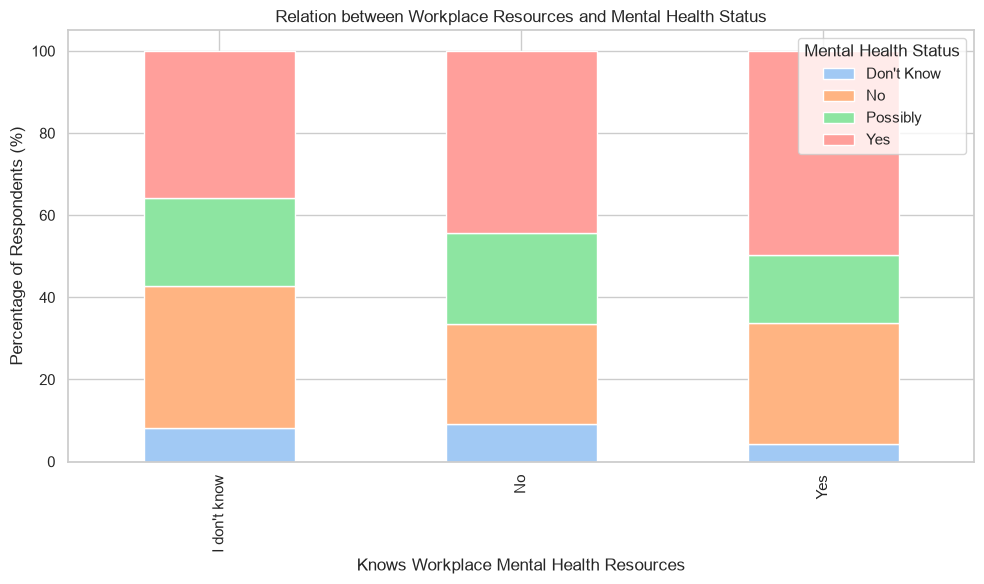

In [76]:
resources_mh_table.plot(kind="bar", color=colors, stacked=True, figsize=(10, 6))
plt.title("Relation between Workplace Resources and Mental Health Status")
plt.xlabel("Knows Workplace Mental Health Resources")
plt.ylabel("Percentage of Respondents (%)")
plt.legend(title="Mental Health Status")
plt.tight_layout()
plt.show()

# Analysis: Employer Discussion of Mental Health vs Mental Health Response
Does the employer's initiative to formally discuss mental health is related with the employees perceptions and responses about their mental health?


In [77]:
discussion_mh_table = pd.crosstab(
    analysis_df["mh_employer_discussion"],
    analysis_df["mental_health"],
    normalize="index"
) * 100
display(discussion_mh_table)

mental_health,Don't Know,No,Possibly,Yes
mh_employer_discussion,,,,
No,9.756098,36.236934,21.777003,32.229965
Yes,3.076923,15.692308,17.538462,63.692308


Among respondents whose employer did not discuss mental health, 35% answered "Yes" to mental_health.
Among respondents whose employer did discuss mental health, 60% answered "Yes".

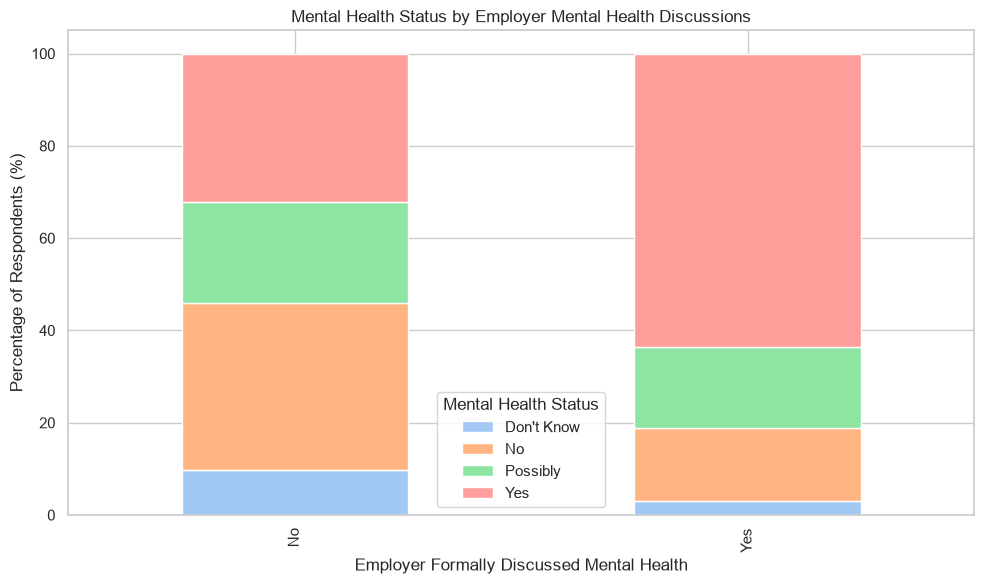

In [78]:
discussion_mh_table.plot(kind="bar", color=colors, stacked=True, figsize=(10, 6))
plt.title("Mental Health Status by Employer Mental Health Discussions")
plt.xlabel("Employer Formally Discussed Mental Health")
plt.ylabel("Percentage of Respondents (%)")
plt.legend(title="Mental Health Status")
plt.tight_layout()
plt.show()

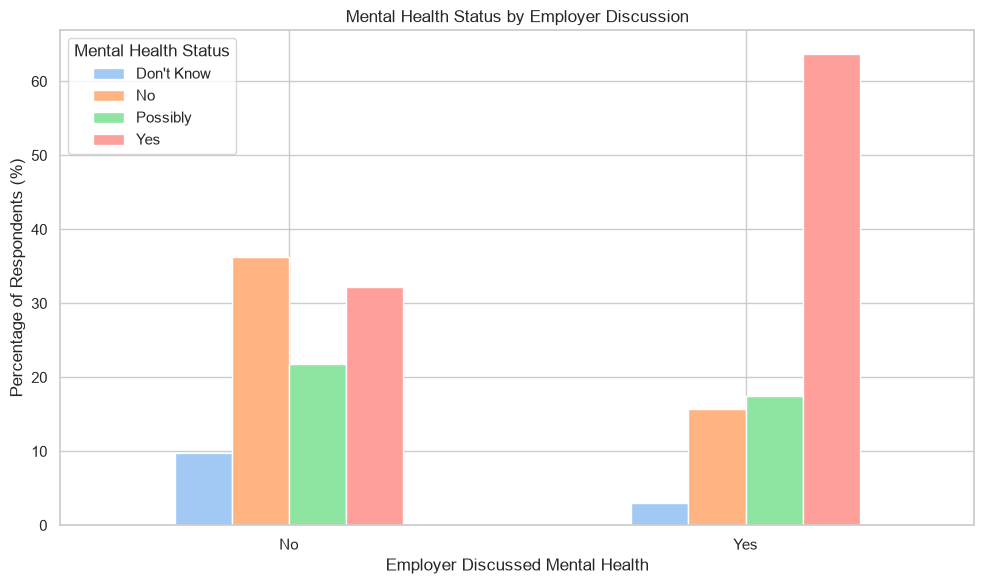

In [79]:
# Grouped bar chart
discussion_mh_table.plot(
    kind="bar",
    stacked=False,
    figsize=(10, 6),
    color=colors
)

plt.title("Mental Health Status by Employer Discussion")
plt.xlabel("Employer Discussed Mental Health")
plt.ylabel("Percentage of Respondents (%)")
plt.legend(title="Mental Health Status")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

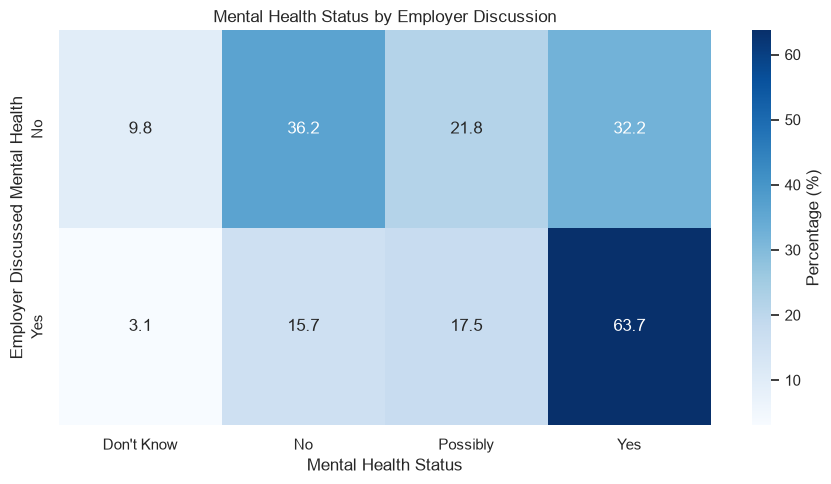

In [80]:
# Heatmap
sns.heatmap(
    discussion_mh_table,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    cbar_kws={"label": "Percentage (%)"}
)

plt.title("Mental Health Status by Employer Discussion")
plt.xlabel("Mental Health Status")
plt.ylabel("Employer Discussed Mental Health")
plt.tight_layout()
plt.show()

# Analyse H2: Organisational communication
Investigating how organisations communicate the different dimensions of support

In [81]:
# Web scraping GitLab benefits page

url = "https://handbook.gitlab.com/handbook/total-rewards/benefits/"

response = requests.get(url)

print(response.status_code)
print(response.headers.get("Content-Type"))

200
text/html; charset=utf-8


In [82]:
response.headers

{'Cache-Control': 'max-age=600', 'Content-Length': '2328056', 'Content-Type': 'text/html; charset=utf-8', 'Etag': '"fc76e97d9abbd58c996c5d9ac728b8cb68e3fa8226ffa8256fe32f0febc07d8b"', 'Expires': 'Sat, 07 Nov 2026 10:03:23 UTC', 'Last-Modified': 'Fri, 06 Nov 2026 22:31:41 GMT', 'Permissions-Policy': 'interest-cohort=()', 'Vary': 'Origin, Accept-Encoding', 'X-Request-Id': '01M6TPTMJSGFS2GX6H7Q3TNAMM', 'Date': 'Sat, 07 Nov 2026 09:53:23 GMT'}

In [83]:
response.raise_for_status()

In [84]:
print(response.text[:1000])

<!doctype html>
<html itemscope itemtype="http://schema.org/WebPage" lang="en" class="no-js" data-theme-init>
  <head>
    <meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1, shrink-to-fit=no">

<meta name="color-scheme" content="light dark">
<meta name="theme-color" media="(prefers-color-scheme: light)" content="#ffffff">
<meta name="theme-color" media="(prefers-color-scheme: dark)"  content="#000000">

<style>
  html { background: Canvas; color: CanvasText; }
  @media (prefers-color-scheme: dark) {
    html { background: #0b0d12; color: #e6e6e6; }
  }
  html[data-theme-init] * { transition: none !important; }
</style>

<script>
  (function() {
    const themeKey = 'td-color-theme';
    const storedTheme = localStorage.getItem(themeKey);
    let theme = storedTheme || (window.matchMedia('(prefers-color-scheme: dark)').matches ? 'dark' : 'light');

    if (theme === 'auto') {
      theme = window.matchMedia('(prefers-color-scheme: dark)').matches 

In [85]:
soup = BeautifulSoup(
    response.text,
    "html.parser"
)

print(type(soup))

<class 'bs4.BeautifulSoup'>


In [86]:
# Inspect what is nested inside what
print(soup.prettify()[:1500])

<!DOCTYPE html>
<html class="no-js" data-theme-init="" itemscope="" itemtype="http://schema.org/WebPage" lang="en">
 <head>
  <meta charset="utf-8"/>
  <meta content="width=device-width, initial-scale=1, shrink-to-fit=no" name="viewport"/>
  <meta content="light dark" name="color-scheme"/>
  <meta content="#ffffff" media="(prefers-color-scheme: light)" name="theme-color"/>
  <meta content="#000000" media="(prefers-color-scheme: dark)" name="theme-color"/>
  <style>
   html { background: Canvas; color: CanvasText; }
  @media (prefers-color-scheme: dark) {
    html { background: #0b0d12; color: #e6e6e6; }
  }
  html[data-theme-init] * { transition: none !important; }
  </style>
  <script>
   (function() {
    const themeKey = 'td-color-theme';
    const storedTheme = localStorage.getItem(themeKey);
    let theme = storedTheme || (window.matchMedia('(prefers-color-scheme: dark)').matches ? 'dark' : 'light');

    if (theme === 'auto') {
      theme = window.matchMedia('(prefers-color-sche

In [87]:
# From website copy outer HTML

html_content = """
<div class="td-content">
  
<h1>Benefits</h1>
  <div class="lead">Overview of GitLab’s Benefit Philosophy and get support with questions</div>
  <header class="article-meta">
    
</header>
  <h2 id="related-benefits-pages">Related Benefits Pages<a class="td-heading-self-link" href="#related-benefits-pages" aria-label="Heading self-link"></a></h2>
<ul>
<li><a href="https://handbook.gitlab.com/handbook/total-rewards/benefits/general-and-entity-benefits/">General &amp; Entity Specific Benefits</a></li>
<li><a href="https://handbook.gitlab.com/handbook/total-rewards/benefits/modern-health/">Modern Health</a></li>
<li><a href="https://handbook.gitlab.com/handbook/total-rewards/benefits/parental-leave-toolkit/">Parental Leave and Return Tool Kit for GitLab Managers and Team Members</a></li>
</ul>
<h2 id="weve-got-you-covered-our-benefits-philosophy">We’ve Got You Covered: Our Benefits Philosophy<a class="td-heading-self-link" href="#weve-got-you-covered-our-benefits-philosophy" aria-label="Heading self-link"></a></h2>
<h3 id="clear-benefits-real-support">Clear Benefits, Real Support<a class="td-heading-self-link" href="#clear-benefits-real-support" aria-label="Heading self-link"></a></h3>
<p>At GitLab, we believe team member Benefits should be simple to understand and there when you need them. From life’s big moments to everyday questions, our comprehensive coverage gives you clarity and confidence so you can focus on your work and life.</p>
<p>Whether you’re planning for the future, starting a family, caring for aging parents, or dealing with unexpected challenges, GitLab’s Benefits are designed to support you at every stage of life—with comprehensive coverage and transparent information when you need it most.</p>
<h3 id="your-support-team-and-resources">Your Support Team and Resources<a class="td-heading-self-link" href="#your-support-team-and-resources" aria-label="Heading self-link"></a></h3>
<p><strong>Need help with your Benefits?</strong> Rest easy knowing you have multiple resources at your fingertips:</p>
<ul>
<li><strong>Start here:</strong> This handbook is your comprehensive guide to understanding GitLab’s Benefit offerings</li>
<li><a href="https://handbook.gitlab.com/handbook/total-rewards/benefits/general-and-entity-benefits/">Company-Wide &amp; Entity/Country Specific Benefits</a> - Complete details on benefits available company-wide and in your location</li>
<li><a href="https://handbook.gitlab.com/handbook/total-rewards/benefits/parental-leave-toolkit/"><strong>Leave Tool Kit for Managers and Team Members</strong></a> - Comprehensive guidance enabling you for life transitions such as parental leave or other types of leave of absence</li>
</ul>
<p><strong>Direct support:</strong> Our Total Rewards team is here to guide you through any questions or life changes. Reach out to us via <a href="https://app.serval.com/new-request">Compass</a>.</p>
<h3 id="our-global-approach">Our Global Approach<a class="td-heading-self-link" href="#our-global-approach" aria-label="Heading self-link"></a></h3>
<h4 id="globally-aligned-locally-relevant">Globally Aligned, Locally Relevant<a class="td-heading-self-link" href="#globally-aligned-locally-relevant" aria-label="Heading self-link"></a></h4>
<p>We recognize that your needs vary depending on where you live and work. That’s why we take a thoughtful, country-specific approach to Benefits rather than a one-size-fits-all solution. We provide competitive Benefit offerings that balance local standards with your needs.</p>
<p>Our country-specific approach considers:</p>
<ul>
<li>Statutory requirements and local regulations</li>
<li>Entity status and headcount considerations</li>
<li>Market practice and standards</li>
<li>Cultural and regional needs</li>
</ul>
<p><strong>What this means for you:</strong></p>
<ul>
<li>Statutory programs are in place in every country where you work</li>
<li>Core medical, life, and pension offerings through statutory or supplementary plans</li>
<li>Country-specific enhancements based on competitive market benchmarking, local needs and regulations</li>
</ul>
<h3 id="our-guiding-principles">Our Guiding Principles<a class="td-heading-self-link" href="#our-guiding-principles" aria-label="Heading self-link"></a></h3>
<h4 id="-continuous-improvement">🔄 Continuous Improvement<a class="td-heading-self-link" href="#-continuous-improvement" aria-label="Heading self-link"></a></h4>
<p>We create new programs with broad reach, high value, and long-term scalability and sustainability. Regular reviews ensure our Benefits evolve with your changing needs, and your feedback directly shapes our offerings.</p>
<h4 id="-inclusive-by-design">🤝 Inclusive by Design<a class="td-heading-self-link" href="#-inclusive-by-design" aria-label="Heading self-link"></a></h4>
<p>Benefits that support all team members, regardless of family structure or life circumstances. We conduct ongoing assessment to ensure our choices reflect our diverse, global team.</p>
<h4 id="-our-credit-values-in-action">💡 Our CREDIT Values in Action<a class="td-heading-self-link" href="#-our-credit-values-in-action" aria-label="Heading self-link"></a></h4>
<p><strong>Collaboration:</strong> We partner with top providers and networks to benchmark against similar companies, fostering understanding across all GitLab entities.</p>
<p><strong>Results:</strong> We make Benefits a meaningful part of your total rewards package, measuring engagement and enrollment to ensure programs truly serve you.</p>
<p><strong>Efficiency:</strong> We streamline processes to make accessing Benefits as simple as possible.</p>
<p><strong>Diversity, Inclusion &amp; Belonging:</strong> We actively ensure our Benefit choices support every team member and regularly assess and improve inclusivity across all programs.</p>
<p><strong>Iteration:</strong> We iterate on improvements based on proven competitive practices and local regulations.</p>
<p><strong>Transparency:</strong> We announce and document our Benefits to keep them updated, share upcoming plans internally before implementing them, and invite discussion and feedback.</p>
<h3 id="how-we-continuously-improve-your-benefits">How We Continuously Improve Your Benefits<a class="td-heading-self-link" href="#how-we-continuously-improve-your-benefits" aria-label="Heading self-link"></a></h3>
<p>Our annual process ensures we’ve got you covered every step of the way:</p>
<h4 id="1-we-listen-to-you">1. We Listen to You<a class="td-heading-self-link" href="#1-we-listen-to-you" aria-label="Heading self-link"></a></h4>
<p>Your voice matters. We carefully review feedback from our Engagement Survey and various team member touchpoints to understand what’s working and where we can better support you.</p>
<h4 id="2-we-research-for-you">2. We Research for You<a class="td-heading-self-link" href="#2-we-research-for-you" aria-label="Heading self-link"></a></h4>
<p>We work with industry experts to benchmark our offerings against other leading tech companies, ensuring you receive competitive total rewards.</p>
<h4 id="3-we-plan-with-you-in-mind">3. We Plan with You in Mind<a class="td-heading-self-link" href="#3-we-plan-with-you-in-mind" aria-label="Heading self-link"></a></h4>
<p>We develop enhancement proposals prioritizing improvements based on market standards, local requirements, headcount limitations, and sustainability.</p>
<h4 id="4-we-explore-every-option">4. We Explore Every Option<a class="td-heading-self-link" href="#4-we-explore-every-option" aria-label="Heading self-link"></a></h4>
<p>We investigate opportunities like multinational pooling to leverage our global presence for better coverage and cost savings that benefit everyone.</p>
<h4 id="5-we-make-informed-decisions">5. We Make Informed Decisions<a class="td-heading-self-link" href="#5-we-make-informed-decisions" aria-label="Heading self-link"></a></h4>
<p>Enhancement proposals are carefully reviewed and approved as part of our annual planning process, ensuring long-term sustainability while meeting your needs.</p>
<h4 id="6-we-keep-you-informed">6. We Keep You Informed<a class="td-heading-self-link" href="#6-we-keep-you-informed" aria-label="Heading self-link"></a></h4>
<ul>
<li><strong>For major changes:</strong> For country specific changes, we create Team Member issues to gather your specific feedback before implementation. We consult and/or inform Works Councils as required.</li>
<li><strong>For smaller changes:</strong> The Total Rewards team may not create an issue for minor adjustments (such as deductible amounts or contribution increases) or legal/required changes for the business.</li>
<li><strong>For all changes:</strong> We track progress and consider your input in our final decisions</li>
<li><strong>Always:</strong> We balance your feedback with market data, budget considerations, and administrative scalability and feasibility</li>
</ul>
<h3 id="7-we-celebrate-improvements-together">7. We Celebrate Improvements Together<a class="td-heading-self-link" href="#7-we-celebrate-improvements-together" aria-label="Heading self-link"></a></h3>
<p>When enhancements are ready, we announce them directly via email, the Loop and/or Slack, and update this handbook immediately so you always have the most current information.</p>
<hr>
<p><em>Remember: Everything at GitLab is always in draft, including our benefits. We’re constantly iterating to better support you. Your feedback and suggestions are always welcome.</em></p>

  <div class="section-index">
  
  
  
  
  
  
  
  <hr class="panel-line">
      
          
          <div class="entry">
              <h5 class="section-summary-header">
                  <a href="https://handbook.gitlab.com/handbook/total-rewards/benefits/general-and-entity-benefits/">General &amp; Entity Specific Benefits &amp; Information</a>
              </h5><div class="section-summary-content">A list of the General &amp; Entity Specific Benefits that GitLab offers as well as other entity-specific information.</div></div>
      
          
          <div class="entry">
              <h5 class="section-summary-header">
                  <a href="https://handbook.gitlab.com/handbook/total-rewards/benefits/parental-leave-toolkit/">Leave of Absence Toolkit for Team Members and Managers</a>
              </h5><div class="section-summary-content">Leave Toolkit for Team Members and Managers</div></div>
      
          
          <div class="entry">
              <h5 class="section-summary-header">
                  <a href="https://handbook.gitlab.com/handbook/total-rewards/benefits/modern-health/">Modern Health</a>
              </h5><div class="section-summary-content">Information on GitLab's Employee Assistance Program.</div></div>
      
  
</div>
<div class="text-muted mt-5 pt-3 border-top">
  Last modified September 11, 2026: <a href="https://gitlab.com/gitlab-com/content-sites/handbook/commit/f511e7a5">compass update (<code>f511e7a5</code>)</a>
</div>





<div class="text-muted pt-3">
<a href="https://gitlab.com/gitlab-com/content-sites/handbook/blob/main/content/handbook/total-rewards/benefits/_index.md" class="td-page-meta--view" target="_blank" rel="noopener">
  <i class="fa fa-file-code fa-fw"></i> View page source
</a>
-
<a href="https://gitlab.com/-/ide/project/gitlab-com/content-sites/handbook/edit/main/-/content/handbook/total-rewards/benefits/_index.md" class="td-page-meta--edit" target="_blank" rel="noopener">
  <i class="fa fa-edit fa-fw"></i> Edit this page
</a>


-
please <a href="https://handbook.gitlab.com/handbook/about/contributing/">contribute</a>.
<a href="https://creativecommons.org/licenses/by-sa/4.0/" target="_blank">
<img alt="Creative Commons License" src="https://i.creativecommons.org/l/by-sa/4.0/80x15.png" style="border-width: 0px;"></a>
</div>

</div>
"""

In [88]:
# Analysing the HTML to get the h2 tags topics
soup_html = BeautifulSoup(html_content, "html.parser")
h2_tags = soup_html.find_all("h2")

print("---Main topics found (h2)---") 
for idx, h2 in enumerate(h2_tags, start=1):
    title_text = h2.get_text(" ", strip=True)
    title_text = title_text.replace("Heading self-link", "").strip()
    print(f"{idx}. {title_text}")

print("\n---Related statistical context (benefits_mh_table)---")
display(benefits_mh_table.round(2))

---Main topics found (h2)---
1. Related Benefits Pages
2. We’ve Got You Covered: Our Benefits Philosophy

---Related statistical context (benefits_mh_table)---


mental_health,Don't Know,No,Possibly,Yes
benefits,,,,
I don't know,13.10,35.37,25.76,25.76
No,7.34,27.52,22.94,42.20
Yes,4.99,26.38,17.47,51.16


In [89]:
# Analysing the HTML to get the h3 tags topics
h3_tags = soup_html.find_all("h3")

print("--- Workplace Resources and Philosophy (h3)---")
for idx, h3 in enumerate(h3_tags, start=1):
    title_h3 = h3.get_text(" ", strip=True)
    title_h3 = title_h3.replace("Heading self-link", "").strip()
    print(f"{idx}.{title_h3}")

--- Workplace Resources and Philosophy (h3)---
1.Clear Benefits, Real Support
2.Your Support Team and Resources
3.Our Global Approach
4.Our Guiding Principles
5.How We Continuously Improve Your Benefits
6.7. We Celebrate Improvements Together
